In [1]:
import numpy as np
import pandas as pd 

from statsmodels.tsa.stattools import adfuller



In [2]:
df= pd.read_csv("1_min_SPY_2008-2021.csv")

In [3]:
# Sort by date
df = df.sort_values('date')
# Drop the column
df = df.drop(columns=['Unnamed: 0'])

# Optional: check the DataFrame
print(df.head())



                     date    open    high     low   close  volume  barCount  \
82740  20080122  07:30:00  126.45  126.82  126.00  126.67   30987      4541   
82741  20080122  07:31:00  126.67  127.17  126.39  127.12   20111      3125   
82742  20080122  07:32:00  127.10  127.13  126.71  126.78   11979      2074   
82743  20080122  07:33:00  126.76  126.90  126.53  126.54    8017      1350   
82744  20080122  07:34:00  126.54  127.18  126.54  126.78   11967      1253   

       average  
82740  126.283  
82741  126.958  
82742  126.922  
82743  126.675  
82744  126.730  


In [4]:
df.isna().sum()

date        0
open        0
high        0
low         0
close       0
volume      0
barCount    0
average     0
dtype: int64

In [5]:
data = df[['close','date','volume']].set_index('date')
data

,close,volume
date,,
20080122 07:30:00,126.67,30987
20080122 07:31:00,127.12,20111
20080122 07:32:00,126.78,11979
20080122 07:33:00,126.54,8017
20080122 07:34:00,126.78,11967
...,...,...
20210506 13:55:00,418.49,9073
20210506 13:56:00,418.64,6680
20210506 13:57:00,418.79,6912


In [6]:
data.index = pd.to_datetime(data.index)

data['day'] = data.index.date

data['return'] = data['close'].apply(np.log).diff()

data = data.groupby('day').apply(lambda x: x.iloc[1:]).reset_index(drop=True)

data

/tmp/ipykernel_178731/4261694121.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data = data.groupby('day').apply(lambda x: x.iloc[1:]).reset_index(drop=True)


,close,volume,day,return
0,127.12,20111,2008-01-22,0.003546
1,126.78,11979,2008-01-22,-0.002678
2,126.54,8017,2008-01-22,-0.001895
3,126.78,11967,2008-01-22,0.001895
4,127.00,18422,2008-01-22,0.001734
...,...,...,...,...
2067482,418.49,9073,2021-05-06,-0.000167
2067483,418.64,6680,2021-05-06,0.000358
2067484,418.79,6912,2021-05-06,0.000358
2067485,418.76,7891,2021-05-06,-0.000072


In [7]:

# Define volatility function
def aggregate_volatility(x):
    return np.sqrt(np.sum(x**2))

# Aggregate daily
data_daily = data.groupby('day').aggregate({
    'return': aggregate_volatility,  # compute daily volatility
    'volume': np.sum                  # sum volume
})

# Rename the aggregated 'return' column to 'daily_volatility'
data_daily.rename(columns={'return': 'daily_volatility'}, inplace=True)

print(data_daily)


            daily_volatility   volume
day                                  
2008-01-22          0.025989  3476383
2008-01-23          0.027646  4103342
2008-01-24          0.017566  2266750
2008-01-25          0.015349  6954399
2008-01-28          0.014580  1904162
...                      ...      ...
2021-04-30          0.005422  1757609
2021-05-03          0.004528   422937
2021-05-04          0.007922   730851
2021-05-05          0.005134   449145
2021-05-06          0.006750   580498

[3347 rows x 2 columns]


/tmp/ipykernel_178731/611944521.py:6: FutureWarning: The provided callable <function sum at 0x7098b07c6680> is currently using SeriesGroupBy.sum. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "sum" instead.
  data_daily = data.groupby('day').aggregate({


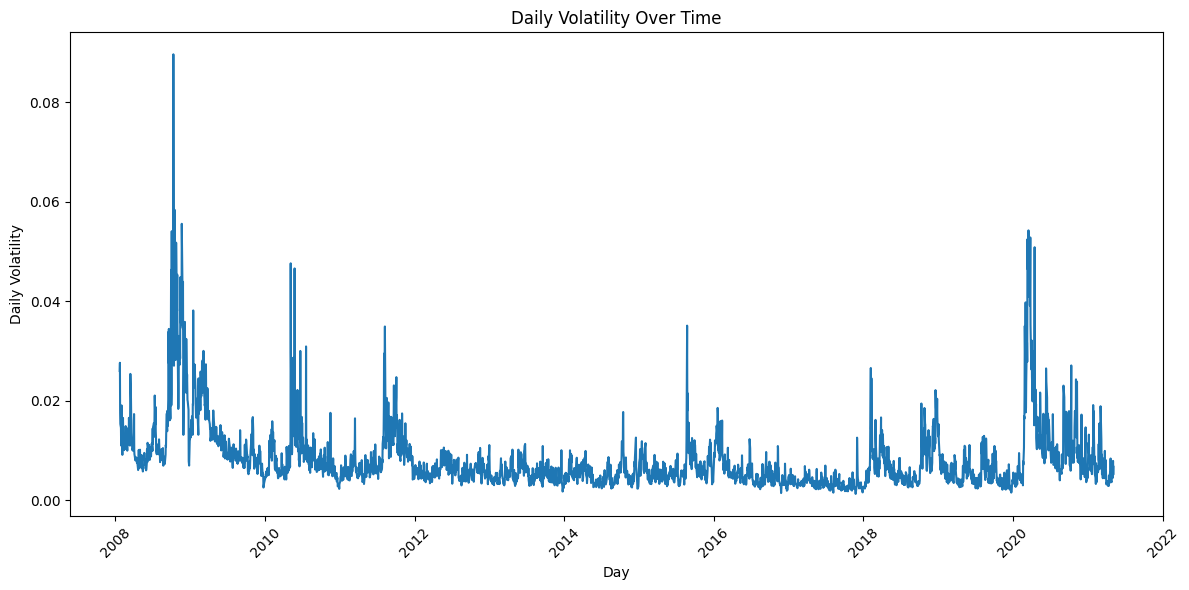

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

# If 'day' is index, reset it to a column for seaborn
data_daily_reset = data_daily.reset_index()

# Plot the daily_volatility series as-is
plt.figure(figsize=(12, 6))
sns.lineplot(x='day', y='daily_volatility', data=data_daily_reset)
plt.xlabel('Day')
plt.ylabel('Daily Volatility')
plt.title('Daily Volatility Over Time')
plt.xticks(rotation=45)  # rotate dates for readability
plt.tight_layout()
plt.show()



In [9]:
data_daily['target'] = data_daily['daily_volatility'].shift(-1)
data_daily['5_day_volatiliy'] = data_daily['daily_volatility'].rolling(5).mean()
data_daily['22_day_volatility'] = data_daily['daily_volatility'].rolling(22).mean()
data_daily = data_daily.dropna().copy()
data_daily.tail()

,daily_volatility,volume,target,5_day_volatiliy,22_day_volatility
day,,,,,
2021-04-29,0.005378,570537,0.005422,0.004181,0.004269
2021-04-30,0.005422,1757609,0.004528,0.004537,0.004208
2021-05-03,0.004528,422937,0.007922,0.004679,0.004216
2021-05-04,0.007922,730851,0.005134,0.005532,0.004430
2021-05-05,0.005134,449145,0.006750,0.005677,0.004492


In [10]:
import statsmodels.api as sm

X = data_daily[['daily_volatility', '5_day_volatiliy', '22_day_volatility']].values
y = data_daily['target'].values
X = sm.add_constant(X)

train_size = 0.8
val_size = 0.2

train_end = int(len(X) * train_size)
#val_end = int(len(X) * (train_size + val_size))

X_train, y_train = X[:train_end], y[:train_end]
#X_val, y_val = X[train_end:val_end], y[train_end:val_end]
X_test, y_test = X[train_end:], y[train_end:]

In [11]:
# Fit the model
model = sm.OLS(y_train, X_train)
ols_result = model.fit()

# Print summary
print(ols_result.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.766
Model:                            OLS   Adj. R-squared:                  0.766
Method:                 Least Squares   F-statistic:                     2903.
Date:                Sat, 08 Nov 2025   Prob (F-statistic):               0.00
Time:                        16:04:57   Log-Likelihood:                 11603.
No. Observations:                2660   AIC:                        -2.320e+04
Df Residuals:                    2656   BIC:                        -2.318e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003      0.000      3.246      0.0

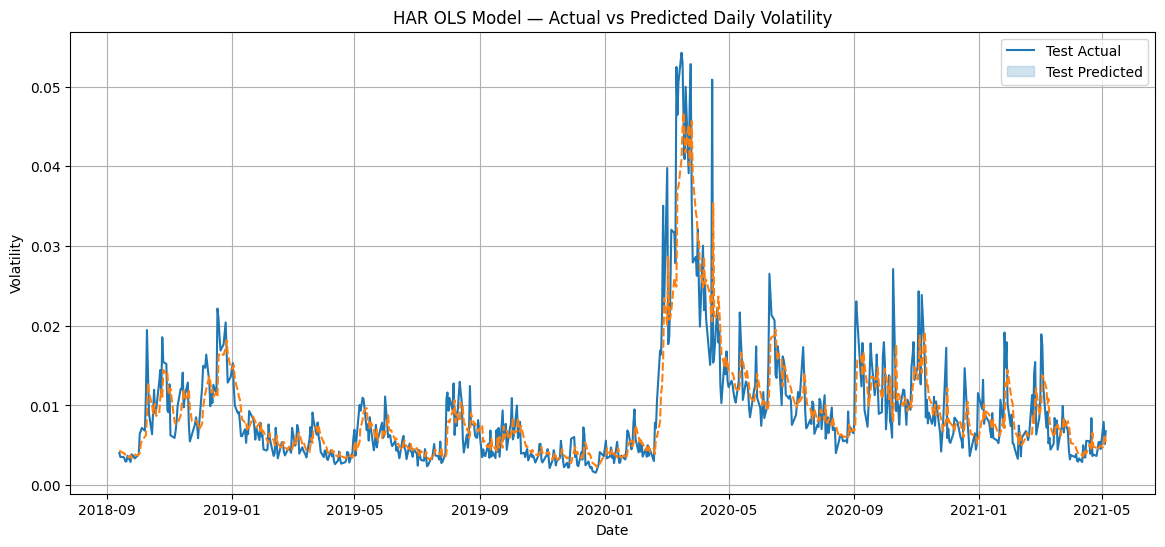

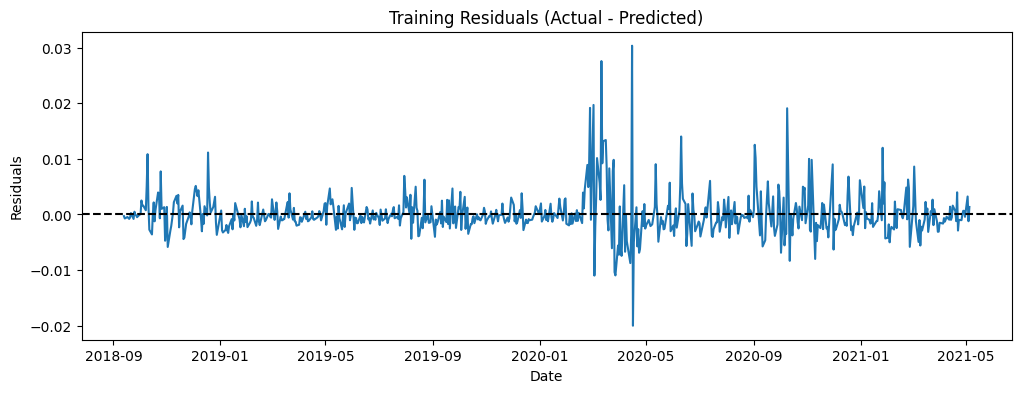

In [12]:
# Build predictions
y_test_pred = ols_result.predict(X_test)


test_plot = pd.DataFrame({
    'date': data_daily.index[len(y_train):],  # start of test set
    'actual_volatility': y_test,
    'predicted_volatility': y_test_pred
}).set_index('date')

# Plot actual vs predicted
plt.figure(figsize=(14,6))
sns.lineplot(data=test_plot[['actual_volatility', 'predicted_volatility']], linestyle='--')
plt.title("HAR OLS Model — Actual vs Predicted Daily Volatility")
plt.xlabel("Date")
plt.ylabel("Volatility")
plt.legend([ "Test Actual", "Test Predicted"])
plt.grid(True)
plt.show()

# Optional: residuals plot
residuals = y_test - y_test_pred
plt.figure(figsize=(12,4))
sns.lineplot(x=test_plot.index, y=residuals)
plt.title("Training Residuals (Actual - Predicted)")
plt.axhline(0, linestyle='--', color='black')
plt.xlabel("Date")
plt.ylabel("Residuals")
plt.show()

In [13]:
from statsmodels.tsa.stattools import adfuller


# Run ADF test
adf_result = adfuller(residuals)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")
for key, value in adf_result[4].items():
    print(f"   {key}: {value}")

# Interpretation
if adf_result[1] < 0.05:
    print("Reject H0: Series is stationary")
else:
    print("Fail to reject H0: Series is non-stationary")

ADF Statistic: -11.65753800556277
p-value: 1.9688969305176288e-21
Critical Values:
   1%: -3.4402666733359175
   5%: -2.8659158113822065
   10%: -2.569100276740811
Reject H0: Series is stationary


In [29]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

# ====== Model Definition ======
class VolatilityNN(nn.Module):
    def __init__(self, input_dim, num_neu=None):
        super(VolatilityNN, self).__init__()
        if num_neu is None:
            # Heuristic with minimum safeguard
            num_neu = max(8, int(np.floor(((len(X_train)-10)/10)/(3+1+1))))
        
        self.model = nn.Sequential(
            nn.Linear(input_dim, num_neu),
            nn.ReLU(),
            nn.Linear(num_neu, num_neu // 2),
            nn.ReLU(),
            nn.Linear(num_neu // 2, 1)  # regression output
        )
    def forward(self, x):
        return self.model(x)


In [41]:

# ====== Dataset Split ======
train_size = int(0.6 * len(X))
val_size   = int(0.2 * len(X))
test_size  = len(X) - train_size - val_size

X_train, y_train = X[:train_size], y[:train_size]
X_val,   y_val   = X[train_size:train_size+val_size], y[train_size:train_size+val_size]
X_test,  y_test  = X[train_size+val_size:], y[train_size+val_size:]

# ====== Convert to Tensors ======
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val,   dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val,   dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test,  dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test,  dtype=torch.float32)

# ====== DataLoaders ======
train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=32, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_tensor,   y_val_tensor),   batch_size=32, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test_tensor,  y_test_tensor),  batch_size=32, shuffle=False)



In [ ]:

# ====== Device ======
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ====== Initialize Model ======
input_dim = X_train_tensor.shape[1]
model = VolatilityNN(input_dim=input_dim).to(device)

# ====== Loss and Optimizer ======
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# ====== Training Loop ======
num_epochs = 500
train_losses, val_losses = [], []

for epoch in range(num_epochs):
    # --- Training ---
    model.train()
    running_train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        outputs = model(X_batch).squeeze(-1)  # safer squeeze
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        
        running_train_loss += loss.item() * X_batch.size(0)
    
    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)
    
    # --- Validation ---
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            outputs = model(X_batch).squeeze(-1)
            loss = criterion(outputs, y_batch)
            running_val_loss += loss.item() * X_batch.size(0)
    
    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)
    
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")



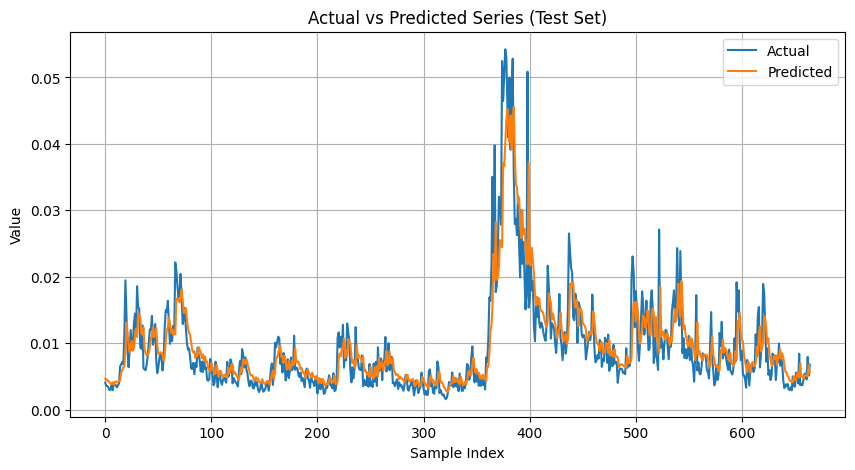

In [45]:
import matplotlib.pyplot as plt

# ====== Predictions on Test Set ======
model.eval()
with torch.no_grad():
    X_test_device = X_test_tensor.to(device)
    y_test_device = y_test_tensor.to(device)
    y_pred = model(X_test_device).squeeze(-1).cpu().numpy()
    y_true = y_test_device.cpu().numpy()

# ====== Plot Actual vs Predicted Series ======
plt.figure(figsize=(10,5))
plt.plot(y_true, label="Actual")
plt.plot(y_pred, label="Predicted"
         )
plt.xlabel("Sample Index")
plt.ylabel("Value")
plt.title("Actual vs Predicted Series (Test Set)")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

# Candidate learning rates
learning_rates = [1e-4, 5e-4, 1e-3, 5e-3, 1e-2]
neurons = range(10,40,5)
# Store results
results = {}

num_epochs = 30  # keep shorter for grid search


for num_neu in neurons:
    for lr in learning_rates:
        print(f"\n=== Training with learning rate {lr} ===")
        
        # Reinitialize model & optimizer for each run
        model = VolatilityNN(input_dim=X_train_tensor.shape[1],num_neu=num_neu).to(device)
        criterion = nn.MSELoss()
        optimizer = optim.Adam(model.parameters(), lr=lr)
        
        train_losses, val_losses = [], []
        
        for epoch in range(num_epochs):
            # --- Training ---
            model.train()
            running_train_loss = 0.0
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                
                optimizer.zero_grad()
                outputs = model(X_batch).squeeze(-1)
                loss = criterion(outputs, y_batch)
                loss.backward()
                optimizer.step()
                
                running_train_loss += loss.item() * X_batch.size(0)
            
            epoch_train_loss = running_train_loss / len(train_loader.dataset)
            train_losses.append(epoch_train_loss)
            
            # --- Validation ---
            model.eval()
            running_val_loss = 0.0
            with torch.no_grad():
                for X_batch, y_batch in val_loader:
                    X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                    outputs = model(X_batch).squeeze(-1)
                    loss = criterion(outputs, y_batch)
                    running_val_loss += loss.item() * X_batch.size(0)
            
            epoch_val_loss = running_val_loss / len(val_loader.dataset)
            val_losses.append(epoch_val_loss)
            
            print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")
        
        # Save final validation loss for this learning rate
        results[lr] = val_losses[-1]

    # ====== Compare Results ======
    print("\n=== Grid Search Results ===")
    for lr, val_loss in results.items():
        print(f"LR={lr:.4f} | Final Val Loss={val_loss:.4f}")

    best_lr = min(results, key=results.get)
    print(f"\nBest learning rate: {best_lr:.4f} (Val Loss={results[best_lr]:.4f})")
